# Task 1: Predict Restaurant Ratings
**Cognifyz Technologies - Machine Learning Internship**
**Intern:** Manish Chandra Raturi
**Dataset:** Restaurant dataset (`Dataset.csv`, 9,551 restaurants, 21 columns)

**Objective:** Build a machine learning model that predicts a restaurant's `Aggregate rating` from its other features.

**Steps:** (1) Preprocess, (2) Train regression models, (3) Evaluate with MSE / RMSE / MAE / R-squared, (4) Interpret the most influential features.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 30, "display.width", 150)

## 2. Load and inspect the data

In [2]:
df = pd.read_csv("Dataset.csv", encoding="utf-8-sig")
print("Shape:", df.shape)
display(df.head(3))
print("\nColumns with missing values:")
print(df.isna().sum()[lambda s: s > 0])

Shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",1100,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,1200,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",4000,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270



Columns with missing values:
Cuisines    9
dtype: int64


## 3. Data quality checks (three issues that would silently ruin the model)

**Issue A - `Aggregate rating = 0` means "not rated", not "terrible".**
**Issue B - `Rating color` and `Rating text` are derived from the target (data leakage).**
**Issue C - Bad coordinates and mixed currencies.**

Restaurants with rating 0: 2148 (22.5%)

Rating text for those rows:
Rating text
Not rated    2148
Name: count, dtype: int64

Votes for those rows (should be ~0):
count    2148.000000
mean        0.870112
max         3.000000
Name: Votes, dtype: float64


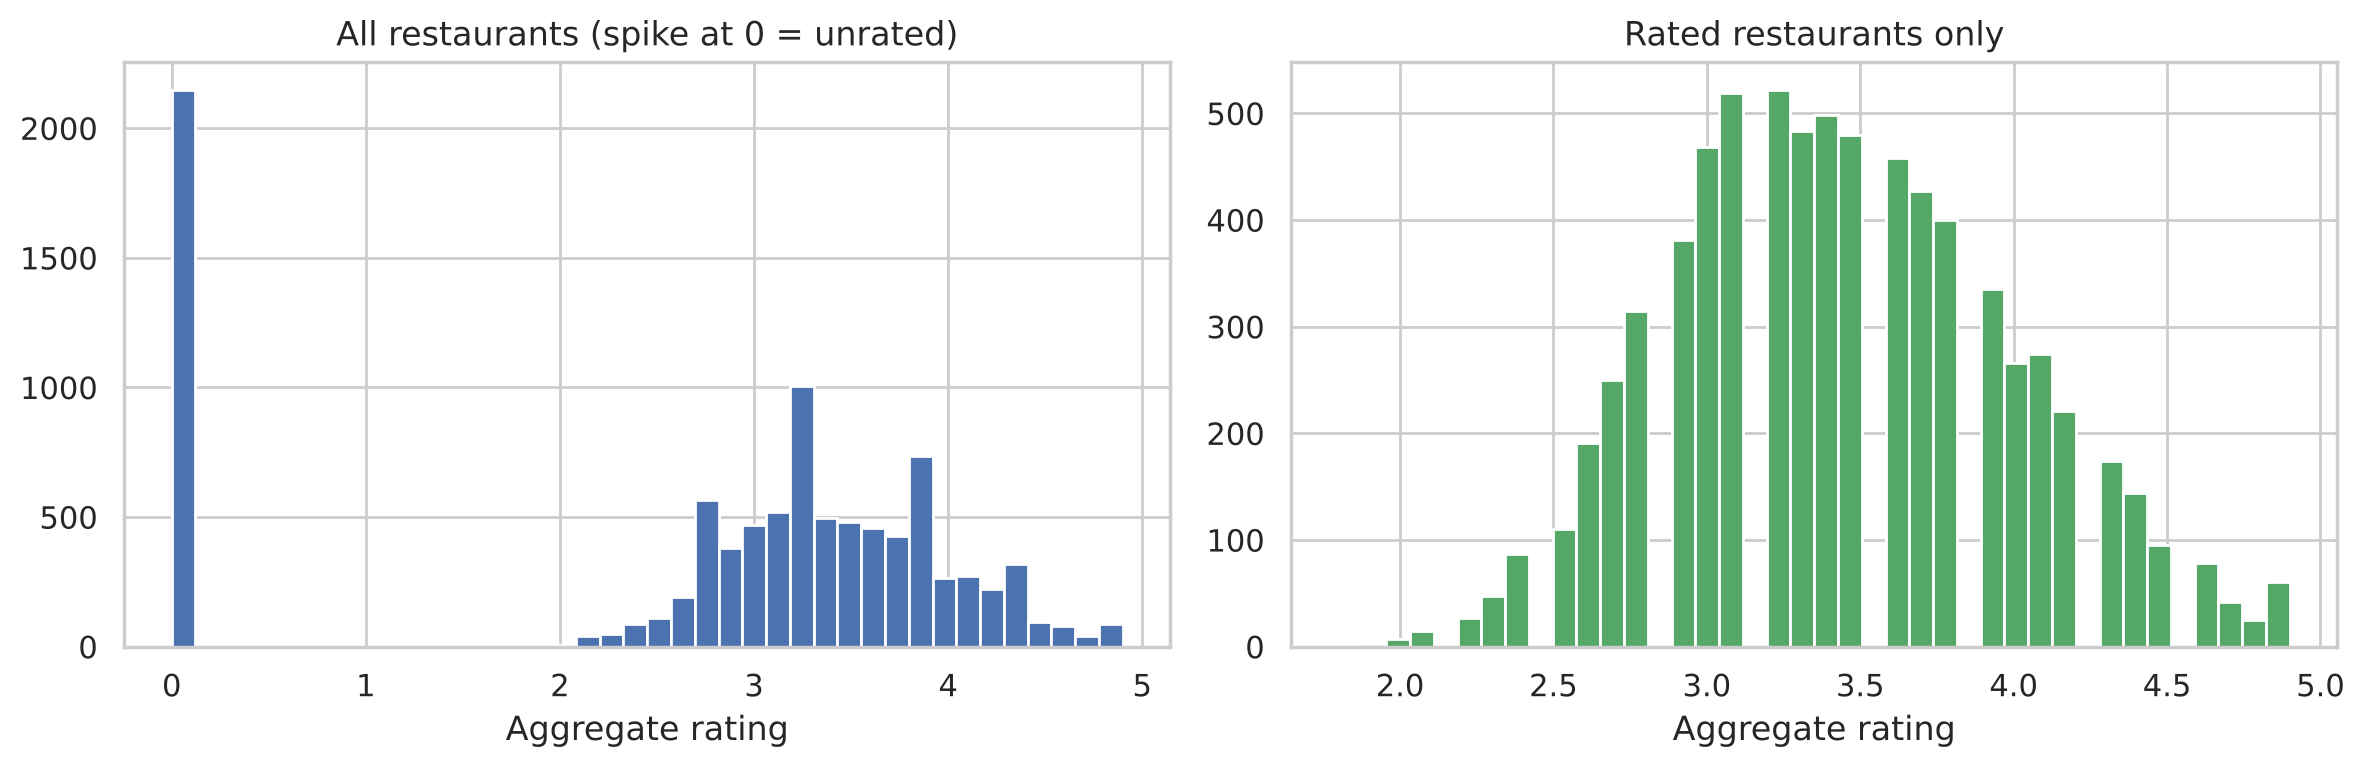

In [3]:
# Issue A: what do the zero ratings really mean?
zero = df["Aggregate rating"] == 0
print("Restaurants with rating 0:", zero.sum(), f"({zero.mean():.1%})")
print("\nRating text for those rows:")
print(df.loc[zero, "Rating text"].value_counts())
print("\nVotes for those rows (should be ~0):")
print(df.loc[zero, "Votes"].describe()[["count", "mean", "max"]])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["Aggregate rating"].hist(bins=40, ax=ax[0], color="#4C72B0")
ax[0].set_title("All restaurants (spike at 0 = unrated)")
df.loc[~zero, "Aggregate rating"].hist(bins=40, ax=ax[1], color="#55A868")
ax[1].set_title("Rated restaurants only")
for a in ax:
    a.set_xlabel("Aggregate rating")
plt.tight_layout(); plt.show()

In [4]:
# Issue B: Rating text / Rating color are a direct re-labelling of the target
leak = df.groupby("Rating text")["Aggregate rating"].agg(["min", "max", "count"]).sort_values("min")
display(leak)
print("Each Rating text covers its own non-overlapping rating band -> using it would let the model read the answer.")

# Issue C: coordinates and currency
print("\nRows with (0, 0) coordinates:", ((df.Latitude == 0) & (df.Longitude == 0)).sum())
print("\nCurrencies in 'Average Cost for two':")
print(df["Currency"].str.replace(r"[^\x00-\x7F]", "", regex=True).value_counts())

,min,max,count
Rating text,,,
Not rated,0.0,0.0,2148
Poor,1.8,2.4,186
Average,2.5,3.4,3737
Good,3.5,3.9,2100
Very Good,4.0,4.4,1079
Excellent,4.5,4.9,301


Each Rating text covers its own non-overlapping rating band -> using it would let the model read the answer.

Rows with (0, 0) coordinates: 497

Currencies in 'Average Cost for two':
Currency
Indian Rupees(Rs.)        8652
Dollar($)                  482
Pounds()                    80
Brazilian Real(R$)          60
Emirati Diram(AED)          60
Rand(R)                     60
NewZealand($)               40
Turkish Lira(TL)            34
Botswana Pula(P)            22
Indonesian Rupiah(IDR)      21
Qatari Rial(QR)             20
Sri Lankan Rupee(LKR)       20
Name: count, dtype: int64


### Cleaning decisions
- **Unrated restaurants (rating 0) are removed from training.** They have no real rating (all labelled *Not rated*, ~0 votes). Keeping them would teach the model a false pattern.
- **`Rating color`, `Rating text` are dropped** (leakage). Also dropped: ID, name, address, locality text (free text / unique per row), `Switch to order menu` (constant), `Currency` (captured by country).
- **Missing `Cuisines`** (9 rows) -> filled with `"Unknown"`.
- **(0, 0) coordinates** -> set to missing and imputed with the median inside the pipeline.
- **`Average Cost for two` is in different currencies**, so it is only comparable inside a country. It is log-transformed and paired with `Country Code`; `Price range` (1-4) is already comparable across countries.

In [5]:
data = df.copy()
data["Cuisines"] = data["Cuisines"].fillna("Unknown")
data.loc[(data.Latitude == 0) & (data.Longitude == 0), ["Latitude", "Longitude"]] = np.nan
data = data[data["Aggregate rating"] > 0].reset_index(drop=True)
print("Rows used for modelling (rated restaurants):", len(data))

# Feature engineering
data["num_cuisines"] = data["Cuisines"].str.split(",").str.len()
data["primary_cuisine"] = data["Cuisines"].str.split(",").str[0].str.strip()
data["table_booking"] = (data["Has Table booking"] == "Yes").astype(int)
data["online_delivery"] = (data["Has Online delivery"] == "Yes").astype(int)
data["delivering_now"] = (data["Is delivering now"] == "Yes").astype(int)
data["log_votes"] = np.log1p(data["Votes"])
data["log_cost"] = np.log1p(data["Average Cost for two"])
data["Country Code"] = data["Country Code"].astype(str)

# Train / test split FIRST, so nothing from the test set influences preprocessing
train_df, test_df = train_test_split(data, test_size=0.2, random_state=RANDOM_STATE)

# Rare categories (city, cuisine) -> "Other", using TRAIN frequencies only
top_cities = train_df["City"].value_counts().head(15).index
top_cuis = train_df["primary_cuisine"].value_counts().head(20).index
for part in (train_df, test_df):
    part["city_group"] = part["City"].where(part["City"].isin(top_cities), "Other")
    part["cuisine_group"] = part["primary_cuisine"].where(part["primary_cuisine"].isin(top_cuis), "Other")

NUM = ["Price range", "num_cuisines", "log_votes", "log_cost", "Latitude", "Longitude",
       "table_booking", "online_delivery", "delivering_now"]
CAT = ["Country Code", "city_group", "cuisine_group"]
TARGET = "Aggregate rating"

X_train, y_train = train_df[NUM + CAT], train_df[TARGET]
X_test, y_test = test_df[NUM + CAT], test_df[TARGET]
print("Train:", X_train.shape, "| Test:", X_test.shape)

Rows used for modelling (rated restaurants): 7403
Train: (5922, 12) | Test: (1481, 12)


## 4. Preprocessing pipeline
Numbers: fill missing with the median, then scale. Categories: one-hot encode (unseen categories are ignored). Everything lives inside a `Pipeline`, so the same steps are applied identically to train and test data.

In [6]:
def make_preprocess(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])

preprocess = make_preprocess(NUM, CAT)

## 5. Train and compare models
A mean-only **baseline** is included. A model that cannot beat it is useless. The decision tree depth is chosen by 5-fold cross-validation on the training set only.

In [7]:
# Choose decision-tree depth by cross-validation (train data only)
tree_search = GridSearchCV(
    Pipeline([("prep", preprocess), ("m", DecisionTreeRegressor(random_state=RANDOM_STATE))]),
    {"m__max_depth": [3, 4, 5, 6, 8, 10, 12], "m__min_samples_leaf": [1, 5, 10, 20]},
    cv=5, scoring="r2", n_jobs=-1)
tree_search.fit(X_train, y_train)
print("Best tree params:", tree_search.best_params_, "| CV R2:", round(tree_search.best_score_, 4))

models = {
    "Baseline (predict mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=tree_search.best_params_["m__max_depth"],
        min_samples_leaf=tree_search.best_params_["m__min_samples_leaf"], random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE),
}

rows, fitted = [], {}
for name, model in models.items():
    pipe = Pipeline([("prep", make_preprocess(NUM, CAT)), ("m", model)])
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=5, scoring="r2", n_jobs=-1).mean()
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    mse = mean_squared_error(y_test, pred)
    rows.append({"Model": name, "MSE": mse, "RMSE": np.sqrt(mse),
                 "MAE": mean_absolute_error(y_test, pred), "R2 (test)": r2_score(y_test, pred),
                 "R2 (5-fold CV, train)": cv_r2})
    fitted[name] = pipe

results = pd.DataFrame(rows).set_index("Model").sort_values("R2 (test)", ascending=False).round(4)
display(results)
results.to_csv("task1_model_comparison.csv")
best_name = results.index[0]
print("Best model on test data:", best_name)

Best tree params: {'m__max_depth': 10, 'm__min_samples_leaf': 20} | CV R2: 0.5199


,MSE,RMSE,MAE,R2 (test),"R2 (5-fold CV, train)"
Model,,,,,
Random Forest,0.1076,0.3280,0.2427,0.6521,0.5938
Gradient Boosting,0.1113,0.3337,0.2495,0.6400,0.5976
Linear Regression,0.1210,0.3478,0.2614,0.6088,0.5646
Decision Tree,0.1322,0.3636,0.2705,0.5726,0.5199
Baseline (predict mean),0.3093,0.5561,0.4552,-0.0001,-0.0003


Best model on test data: Random Forest


## 6. Evaluate the best model

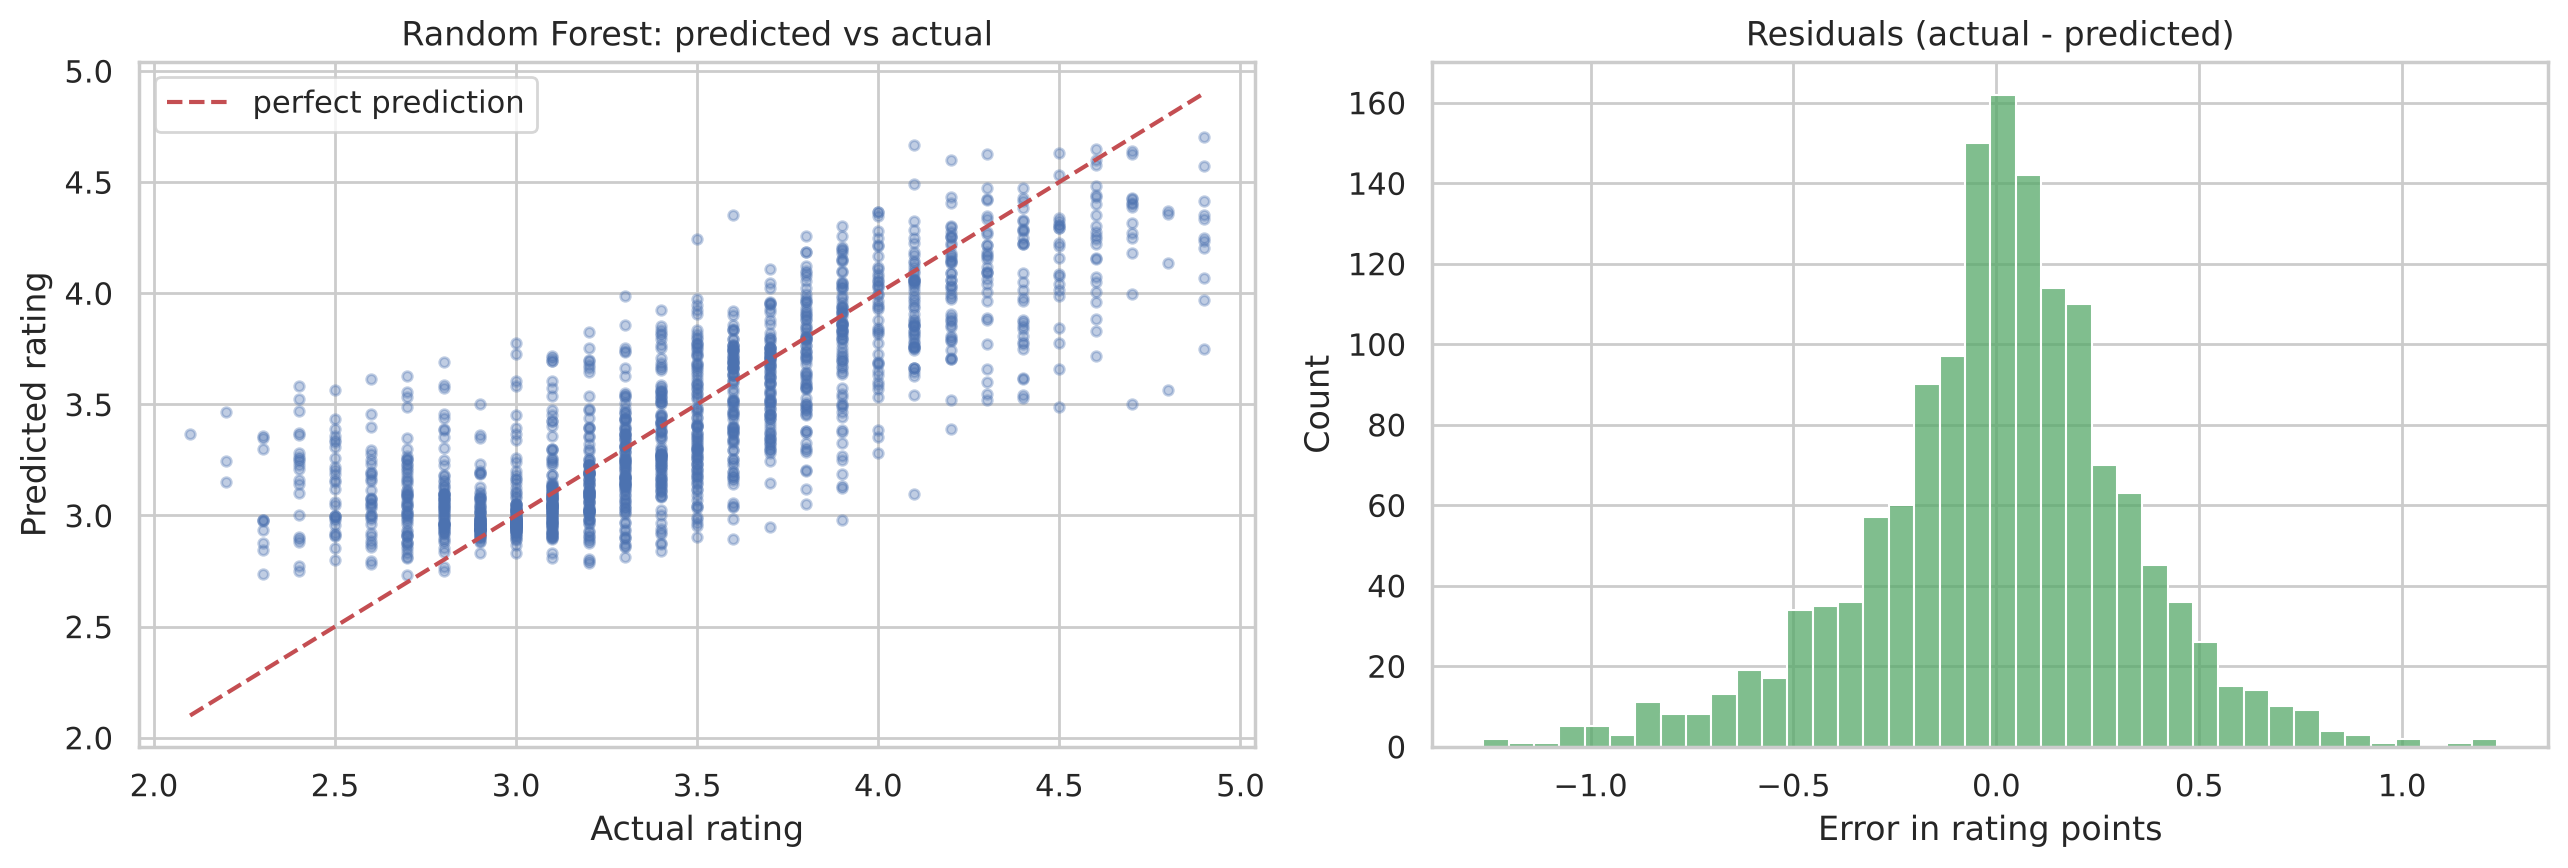

Typical error (MAE): 0.243 rating points
Share of predictions within +/-0.3 of the true rating: 69.6%
Share within +/-0.5: 88.0%


In [8]:
best = fitted[best_name]
pred = best.predict(X_test)
resid = y_test - pred

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(y_test, pred, alpha=0.35, s=12, color="#4C72B0")
lims = [y_test.min(), y_test.max()]
ax[0].plot(lims, lims, "r--", label="perfect prediction")
ax[0].set_xlabel("Actual rating"); ax[0].set_ylabel("Predicted rating")
ax[0].set_title(f"{best_name}: predicted vs actual"); ax[0].legend()
sns.histplot(resid, bins=40, ax=ax[1], color="#55A868")
ax[1].set_title("Residuals (actual - predicted)"); ax[1].set_xlabel("Error in rating points")
plt.tight_layout(); plt.savefig("task1_predicted_vs_actual.png", dpi=130); plt.show()

print(f"Typical error (MAE): {mean_absolute_error(y_test, pred):.3f} rating points")
print(f"Share of predictions within +/-0.3 of the true rating: {(resid.abs() <= 0.3).mean():.1%}")
print(f"Share within +/-0.5: {(resid.abs() <= 0.5).mean():.1%}")

## 7. Interpretation: which features influence ratings?
**Permutation importance** shuffles one feature at a time on the test set and measures how much R-squared drops. It is computed on the original columns (not on one-hot fragments), so results are easy to read.

,feature,importance,std
2,log_votes,0.6557,0.0327
10,city_group,0.0981,0.0081
11,cuisine_group,0.0703,0.0083
5,Longitude,0.0560,0.0058
4,Latitude,0.0339,0.0045
3,log_cost,0.0298,0.0062
7,online_delivery,0.0071,0.0015
9,Country Code,0.0059,0.0009
1,num_cuisines,0.0022,0.0011
0,Price range,0.0014,0.0009


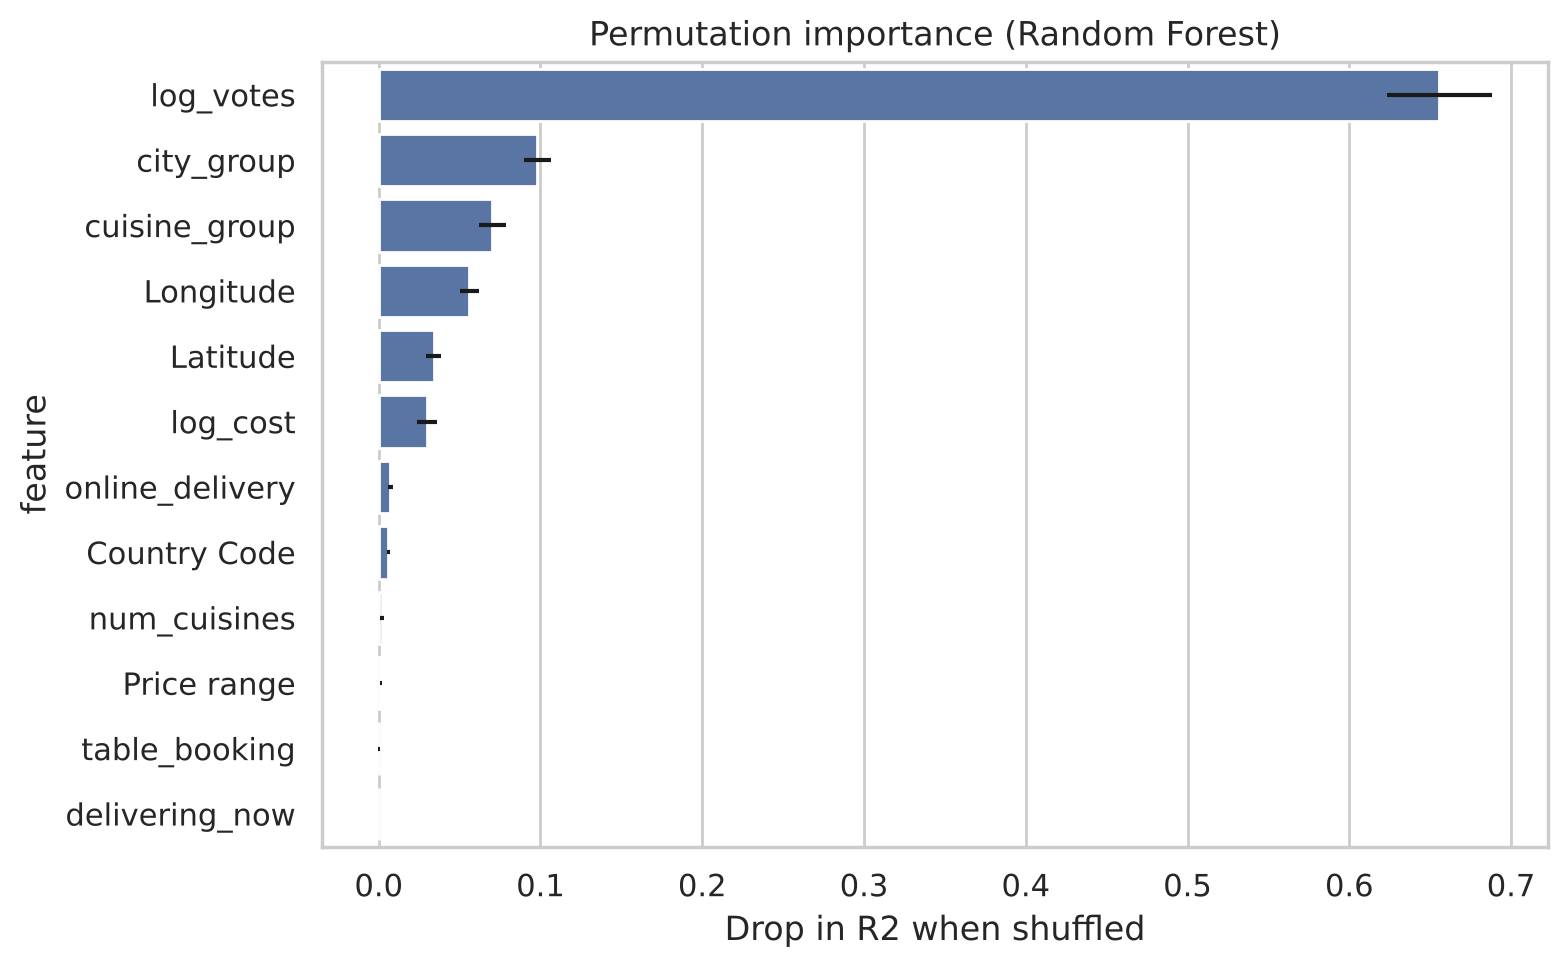

In [9]:
perm = permutation_importance(best, X_test, y_test, n_repeats=15, random_state=RANDOM_STATE, scoring="r2", n_jobs=-1)
imp = pd.DataFrame({"feature": X_test.columns, "importance": perm.importances_mean, "std": perm.importances_std}) \
        .sort_values("importance", ascending=False)
display(imp.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(data=imp, y="feature", x="importance", color="#4C72B0", xerr=imp["std"])
plt.title(f"Permutation importance ({best_name})"); plt.xlabel("Drop in R2 when shuffled")
plt.tight_layout(); plt.savefig("task1_feature_importance.png", dpi=130); plt.show()

In [10]:
# Direction of effect: standardised coefficients of the linear model (numeric features only)
lin = fitted["Linear Regression"]
names = lin.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lin.named_steps["m"].coef_, index=names)
num_coefs = coefs[[n for n in names if n.startswith("num__")]].rename(lambda s: s.replace("num__", ""))
print("Linear-model coefficients for numeric features (per 1 std-dev change):")
print(num_coefs.sort_values(ascending=False).round(3))

Linear-model coefficients for numeric features (per 1 std-dev change):
log_votes          0.280
Price range        0.047
table_booking      0.003
delivering_now    -0.003
log_cost          -0.013
num_cuisines      -0.016
online_delivery   -0.023
Latitude          -0.043
Longitude         -0.073
dtype: float64


### Robustness check: how much does the model depend on `Votes`?
`Votes` counts how many people rated a restaurant. It is available for rated restaurants but it is a *popularity* signal, not a quality cause. Removing it shows how much of the model's skill depends on it.

In [11]:
NUM_NV = [c for c in NUM if c != "log_votes"]
rf_params = dict(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)
pipe_nv = Pipeline([("prep", make_preprocess(NUM_NV, CAT)), ("m", RandomForestRegressor(**rf_params))])
pipe_nv.fit(X_train[NUM_NV + CAT], y_train)
p_nv = pipe_nv.predict(X_test[NUM_NV + CAT])
full_r2 = results.loc["Random Forest", "R2 (test)"]
print(f"Random Forest WITH votes    : R2 = {full_r2:.3f}")
print(f"Random Forest WITHOUT votes : R2 = {r2_score(y_test, p_nv):.3f}, MAE = {mean_absolute_error(y_test, p_nv):.3f}")

Random Forest WITH votes    : R2 = 0.652
Random Forest WITHOUT votes : R2 = 0.541, MAE = 0.291


## 8. Conclusions

**Result**
- Best model: **Random Forest**. Test R-squared **0.652**, RMSE **0.328**, MAE **0.243** rating points. The mean-only baseline scores R-squared 0.000, so the model learns real signal.
- Ranking (test R-squared): Random Forest 0.652 > Gradient Boosting 0.640 > Linear Regression 0.609 > Decision Tree 0.573 > baseline 0.000.
- **69.6%** of predictions are within 0.3 of the true rating and **88.0%** within 0.5.
- Cross-validation R-squared on the training set is lower (about 0.59 for the best models) than the single test split (0.65). The CV number is the more cautious estimate of real-world performance.

**What drives ratings (permutation importance, drop in R-squared)**
- **Votes: 0.656.** By far the strongest signal. Restaurants with more votes rate higher (linear model: +0.28 rating points per standard deviation of log votes).
- **City: 0.098**, **cuisine: 0.070**, **longitude / latitude: 0.056 / 0.034**, **cost for two: 0.030**.
- Price range, table booking, online delivery, number of cuisines and delivering-now are close to zero once votes, city and cost are known (their information overlaps with those features).

**Important caveats (read before using this model)**
- `Votes` is a *popularity* signal, not a cause of quality. It only exists once people have already reviewed a restaurant, so the model could not rate a brand-new place. Without votes, Random Forest drops to R-squared **0.541** (MAE 0.291). That version is the honest estimate for new restaurants.
- About a third of the variation is unexplained. Food quality, service and ambience are not in the data.
- 2,148 unrated restaurants (rating 0, 22.5% of rows) were excluded, and `Rating text` / `Rating color` were dropped because they are the target in disguise.
- Average cost is in different currencies, so it is only useful together with country; `Price range` is the safer cross-country measure.